# Bedrock Depth Interpolation Module

This notebook provides a comprehensive guide to using the bedrock depth interpolation module for spatial analysis of geological data.

## Overview

The module provides tools for:
- Interpolating bedrock depth/altitude from scattered borehole measurements
- Using Inverse Distance Weighting (IDW) algorithm
- Converting between altitude and depth using DEMs
- Outputting georeferenced GeoTIFF rasters

## Installation

First, install the required dependencies:

In [1]:
# Install required packages
!py -m pip install numpy scipy rasterio pandas matplotlib


[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: C:\Users\samue\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


## Import the Module

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from geo_earthworm import GeoEarthworm as gew

# Set random seed for reproducibility
np.random.seed(42)

---

# Example 1: Basic Interpolation

Let's start with a simple example using synthetic borehole data.

In [3]:
# Create sample borehole data (lon, lat, bedrock depth in meters)
points = {
    'lon': [-122.5, -122.4, -122.6, -122.45, -122.55, -122.5, -122.4],
    'lat': [37.8, 37.9, 37.85, 37.95, 37.75, 37.88, 37.82],
    'bedrock': [150, 180, 160, 200, 140, 170, 165]
}

print(f"Number of points: {len(points['lon'])}")
print(f"bedrock range: {min(points['bedrock'])} - {max(points['bedrock'])} meters")

Number of points: 7
bedrock range: 140 - 200 meters


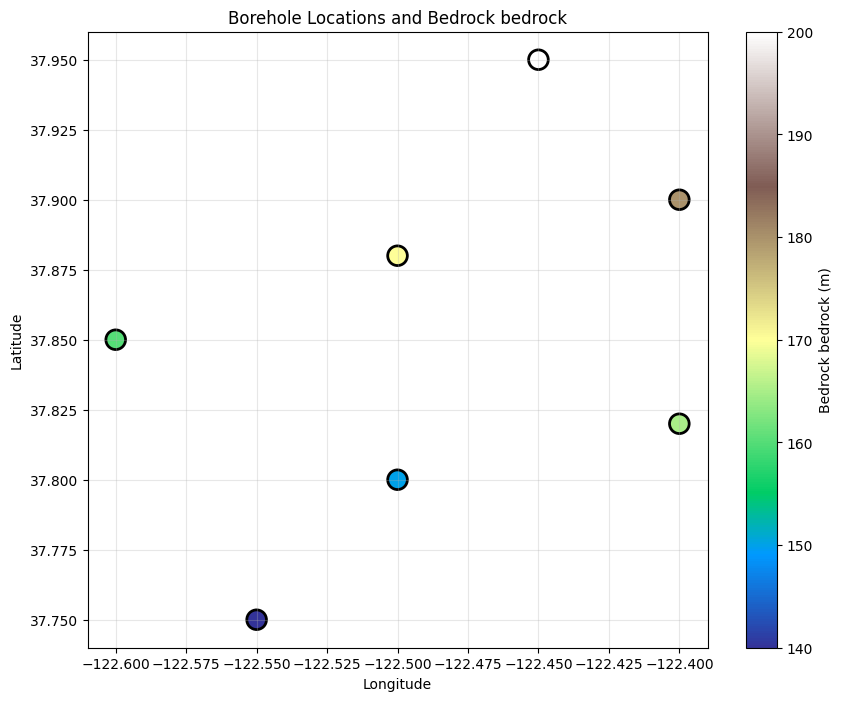

In [4]:
# Visualize borehole locations
plt.figure(figsize=(10, 8))
scatter = plt.scatter(points['lon'], points['lat'], 
                     c=points['bedrock'], cmap='terrain', 
                     s=200, edgecolors='black', linewidths=2)
plt.colorbar(scatter, label='Bedrock bedrock (m)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Borehole Locations and Bedrock bedrock')
plt.grid(True, alpha=0.3)
plt.show()

In [5]:
# Create interpolator
interpolator = gew(
    lon=points['lon'],
    lat=points['lat'],
    bedrock=points['bedrock'],
    epsg=4326,              # WGS84 coordinate system
    is_altitude=True        # Input values are bedrocks
)

# Print input statistics
stats = interpolator.get_statistics()
print("\nInput Data Statistics:")
print(f"  Min: {stats['min']:.1f} m")
print(f"  Max: {stats['max']:.1f} m")
print(f"  Mean: {stats['mean']:.1f} m")
print(f"  Std Dev: {stats['std']:.1f} m")
print(f"  Count: {stats['count']} points")


Input Data Statistics:
  Min: 140.0 m
  Max: 200.0 m
  Mean: 166.4 m
  Std Dev: 18.3 m
  Count: 7 points


In [6]:
# Define bounding box and interpolate
bbox = (-122.7, 37.7, -122.3, 38.0)  # (min_lon, min_lat, max_lon, max_lat)

result, transform = interpolator.interpolate_to_raster(
    bbox=bbox,
    resolution=0.001,                # ~1 km grid cells
    output_path="bedrock_depth.tif",
    power=2.0,                      # Standard IDW
    output_depth=False              # Output bedrock (no DEM)
)

print(f"\nOutput raster shape: {result.shape}")

Raster saved to: bedrock_depth.tif
Dimensions: 300 rows x 401 cols
Resolution: 0.001
EPSG: 4326

Output raster shape: (300, 401)


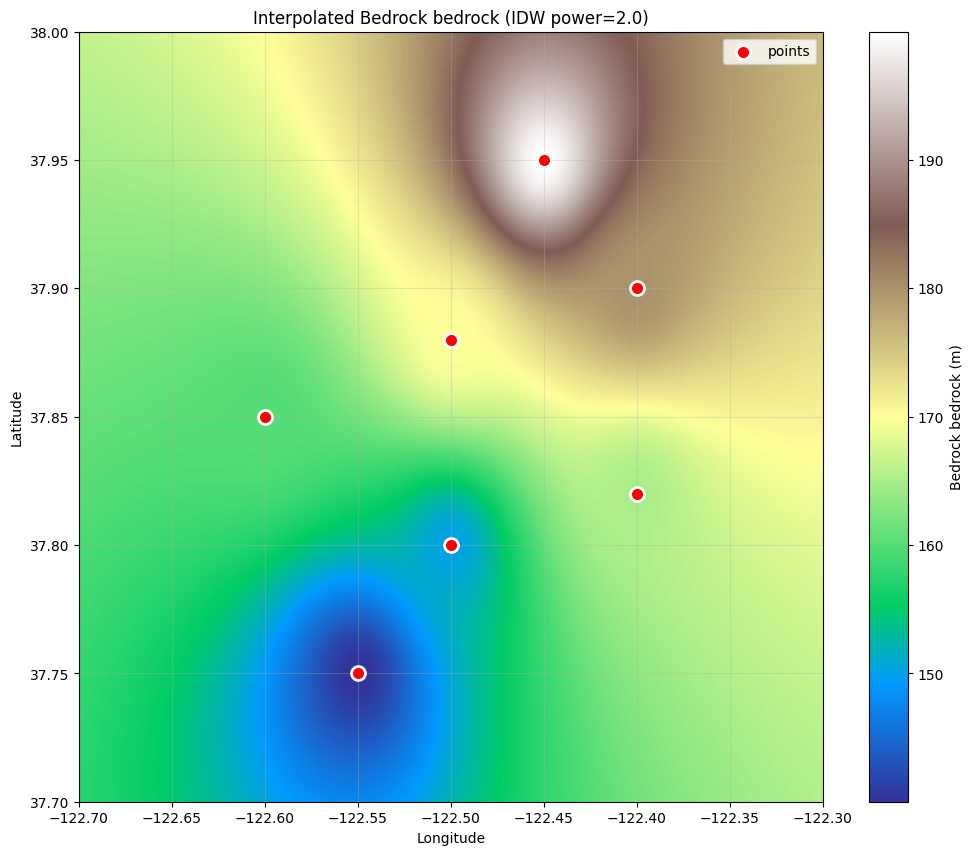

In [7]:
# Visualize the interpolated surface
plt.figure(figsize=(12, 10))
plt.imshow(result, extent=[bbox[0], bbox[2], bbox[1], bbox[3]], 
           origin='upper', cmap='terrain', aspect='auto')
plt.colorbar(label='Bedrock bedrock (m)')
plt.scatter(points['lon'], points['lat'], 
           c='red', s=100, edgecolors='white', linewidths=2, 
           label='points', zorder=5)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Interpolated Bedrock bedrock (IDW power=2.0)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

---

# Example 2: Exploring IDW Parameters

The power parameter controls how much influence nearby points have compared to distant points.

In [8]:
# Generate denser synthetic data for better visualization
n_points = 50
lon = np.random.uniform(-122.7, -122.3, n_points)
lat = np.random.uniform(37.7, 38.0, n_points)

# Create synthetic bedrock pattern with some structure
bedrock_bedrock = 200 + 50 * np.sin(lon * 10) + 30 * np.cos(lat * 10)
bedrock_bedrock += np.random.normal(0, 10, n_points)  # Add noise

interpolator = gew(
    lon=lon,
    lat=lat,
    bedrock=bedrock_bedrock,
    epsg=4326,
    is_altitude=True
)

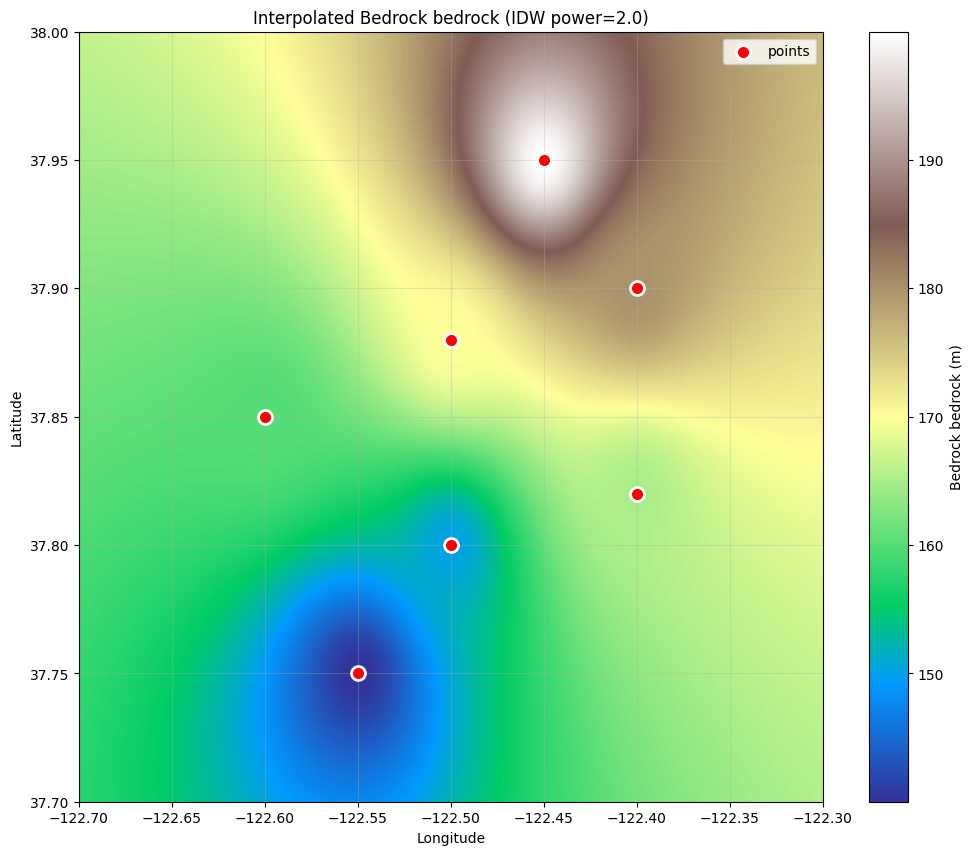

In [9]:
# Visualize the interpolated surface
plt.figure(figsize=(12, 10))
plt.imshow(result, extent=[bbox[0], bbox[2], bbox[1], bbox[3]], 
           origin='upper', cmap='terrain', aspect='auto')
plt.colorbar(label='Bedrock bedrock (m)')
plt.scatter(points['lon'], points['lat'], 
           c='red', s=100, edgecolors='white', linewidths=2, 
           label='points', zorder=5)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Interpolated Bedrock bedrock (IDW power=2.0)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Raster saved to: bedrock_power1.0.tif
Dimensions: 30 rows x 41 cols
Resolution: 0.01
EPSG: 4326
Raster saved to: bedrock_power2.0.tif
Dimensions: 30 rows x 41 cols
Resolution: 0.01
EPSG: 4326
Raster saved to: bedrock_power3.0.tif
Dimensions: 30 rows x 41 cols
Resolution: 0.01
EPSG: 4326
Raster saved to: bedrock_power5.0.tif
Dimensions: 30 rows x 41 cols
Resolution: 0.01
EPSG: 4326


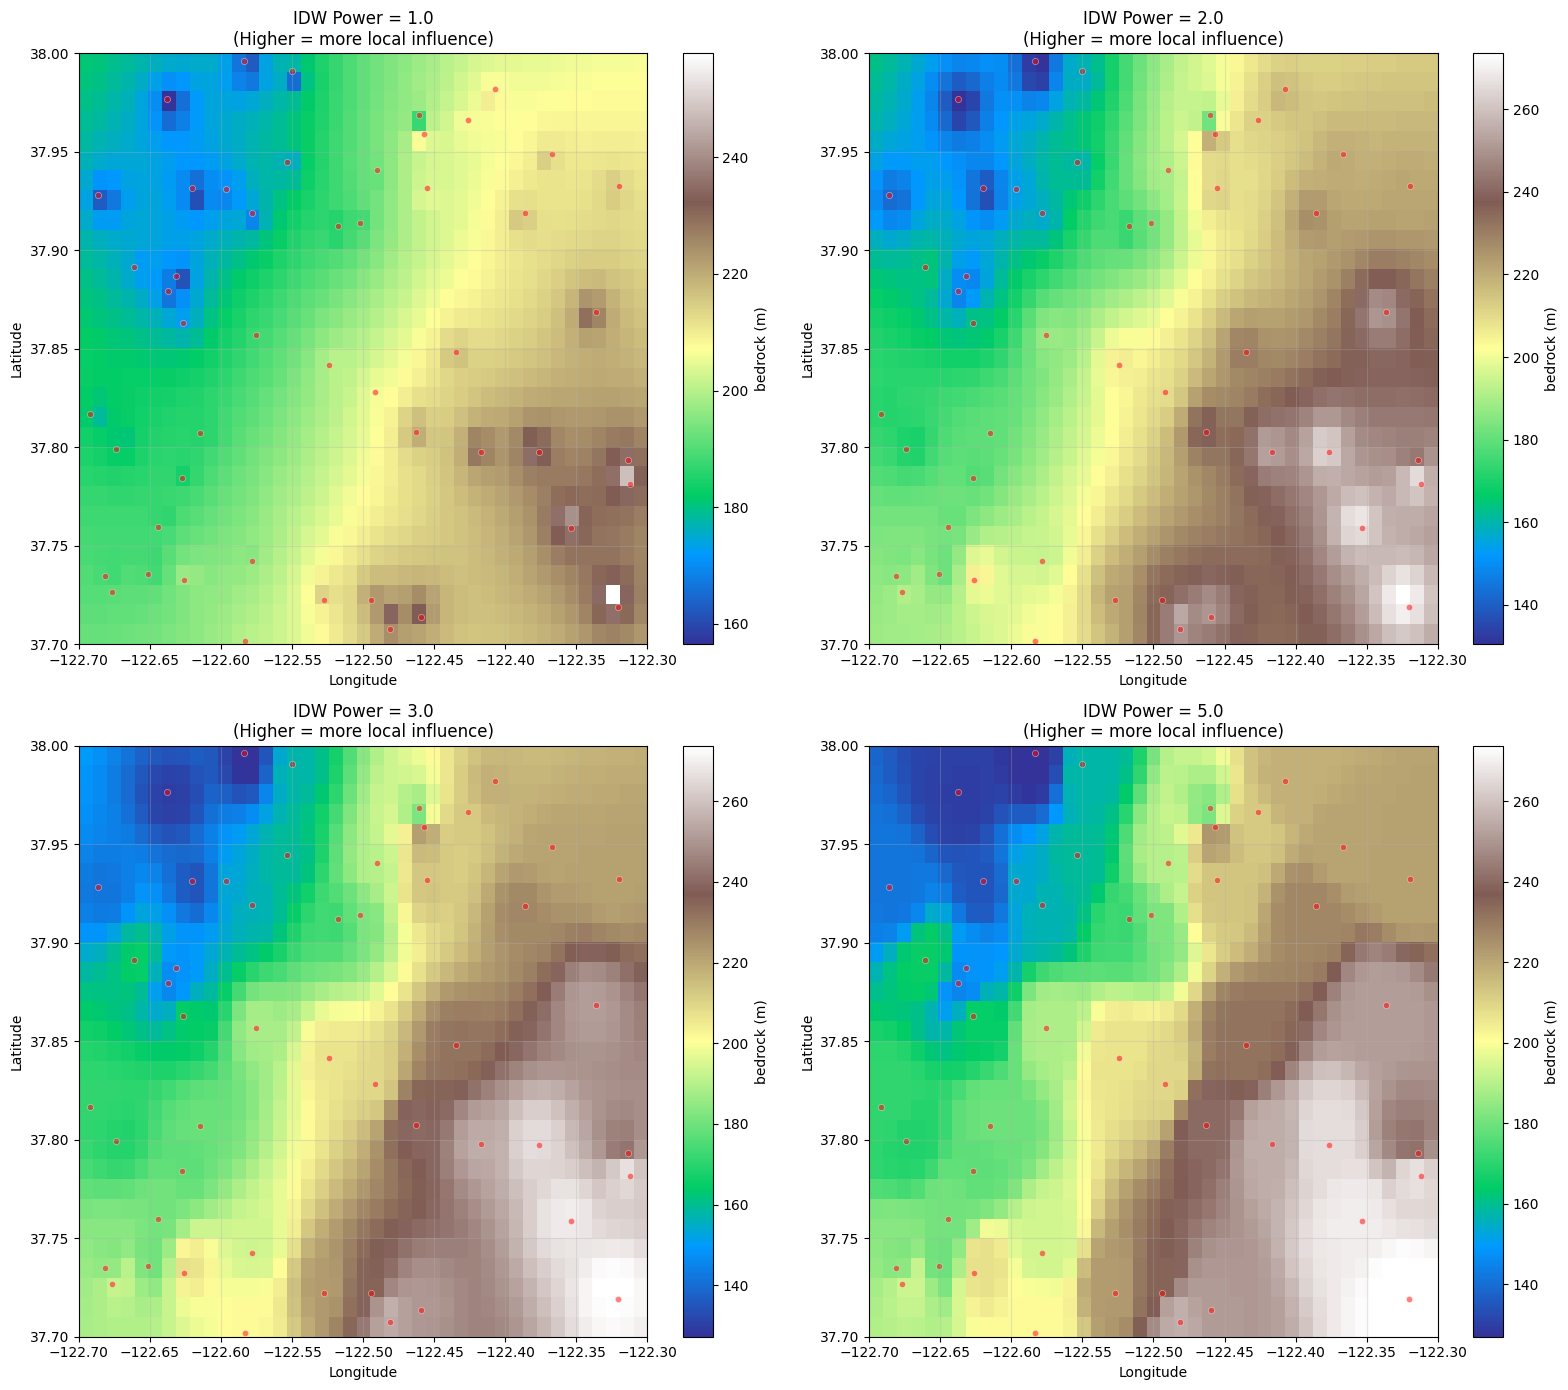

In [10]:
# Compare different power values
powers = [1.0, 2.0, 3.0, 5.0]
bbox = (-122.7, 37.7, -122.3, 38.0)

fig, axes = plt.subplots(2, 2, figsize=(16, 14))
axes = axes.ravel()

for i, power in enumerate(powers):
    result, _ = interpolator.interpolate_to_raster(
        bbox=bbox,
        resolution=0.01,
        output_path=f"bedrock_power{power}.tif",
        power=power,
        output_depth=False
    )
    
    im = axes[i].imshow(result, extent=[bbox[0], bbox[2], bbox[1], bbox[3]], 
                        origin='upper', cmap='terrain', aspect='auto')
    axes[i].scatter(lon, lat, c='red', s=20, alpha=0.5, edgecolors='white', linewidths=0.5)
    axes[i].set_xlabel('Longitude')
    axes[i].set_ylabel('Latitude')
    axes[i].set_title(f'IDW Power = {power}\n(Higher = more local influence)')
    axes[i].grid(True, alpha=0.3)
    plt.colorbar(im, ax=axes[i], label='bedrock (m)')

plt.tight_layout()
plt.show()

---

# Example 3: Using Max Neighbors

Limiting the number of neighbors can speed up computation and create more localized interpolation.

Raster saved to: bedrock_neighbors0.tif
Dimensions: 30 rows x 41 cols
Resolution: 0.01
EPSG: 4326
Raster saved to: bedrock_neighbors1.tif
Dimensions: 30 rows x 41 cols
Resolution: 0.01
EPSG: 4326
Raster saved to: bedrock_neighbors2.tif
Dimensions: 30 rows x 41 cols
Resolution: 0.01
EPSG: 4326
Raster saved to: bedrock_neighbors3.tif
Dimensions: 30 rows x 41 cols
Resolution: 0.01
EPSG: 4326


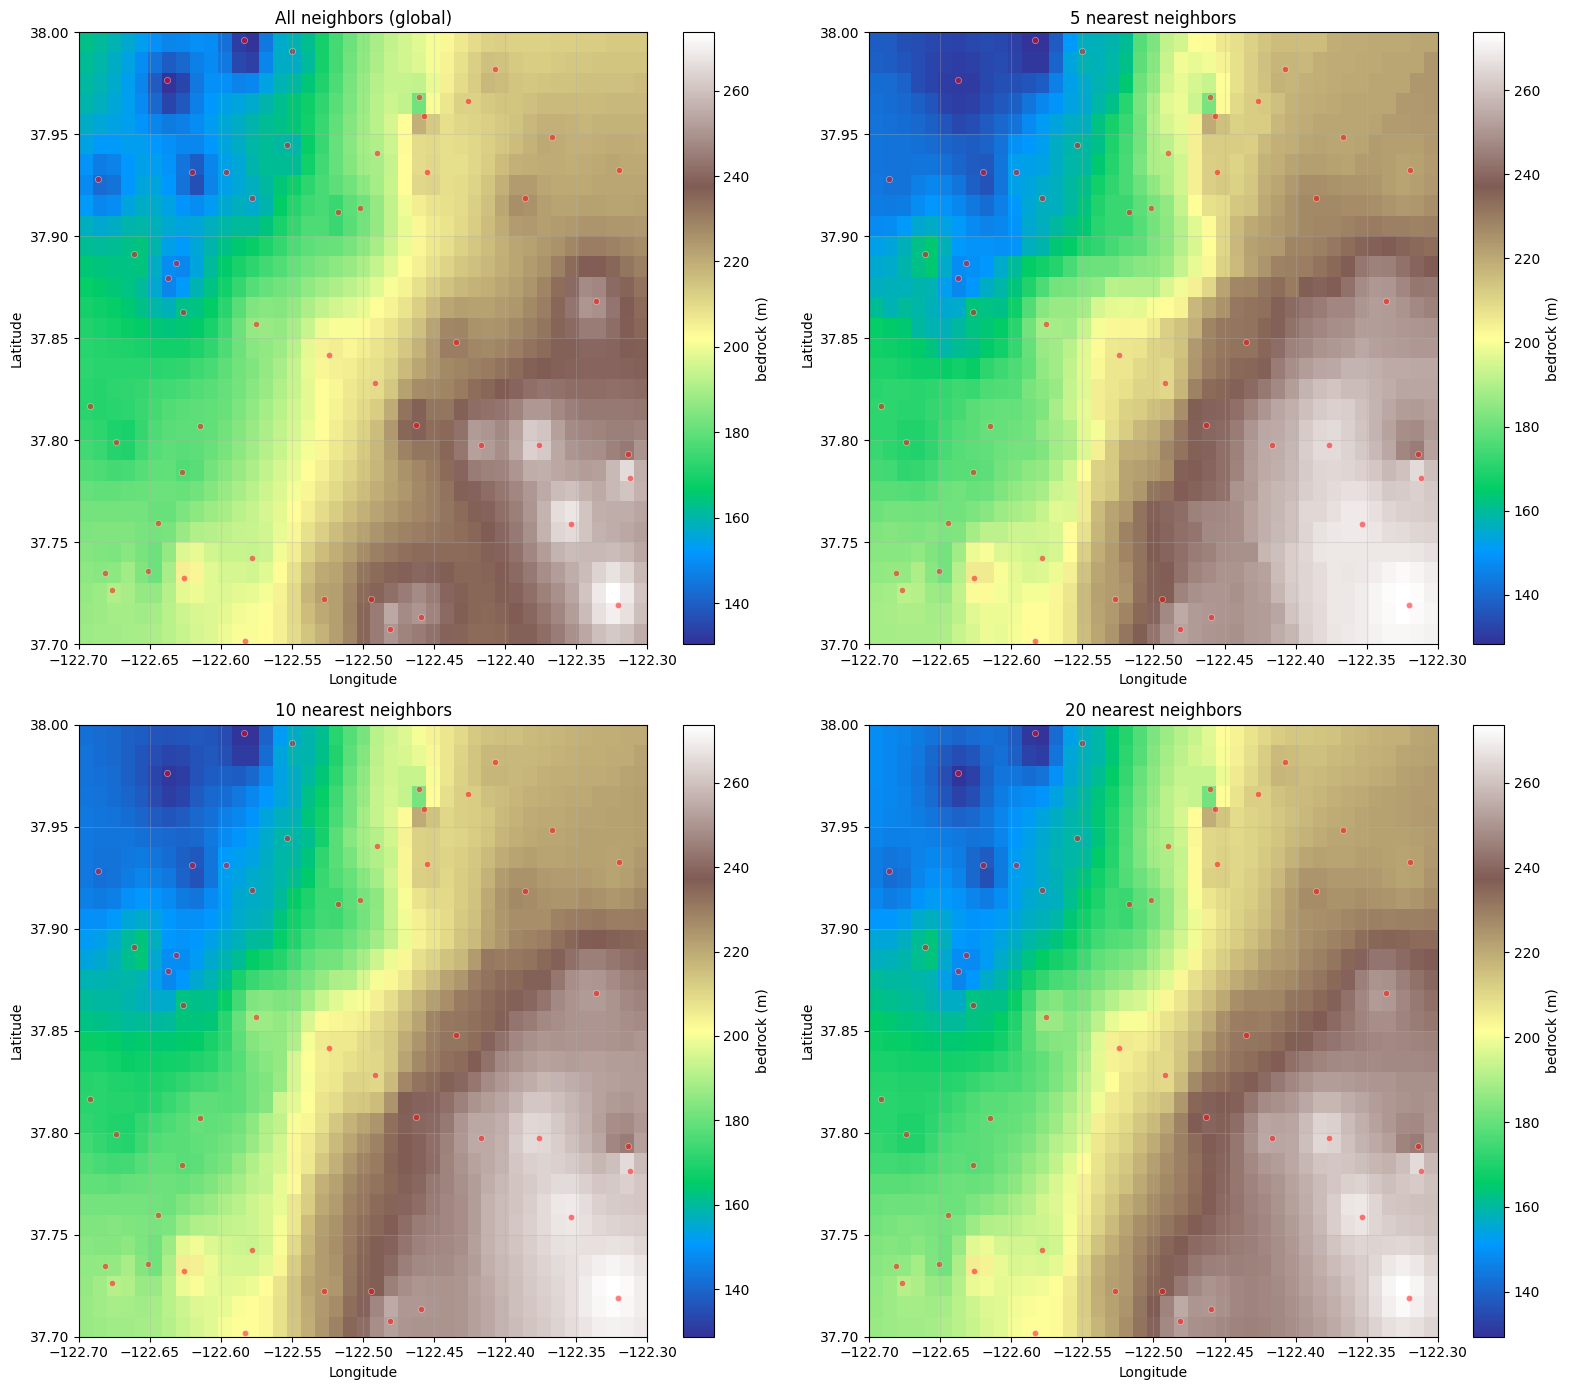

In [11]:
# Compare different max_neighbors settings
neighbor_configs = [
    {'max_neighbors': None, 'label': 'All neighbors (global)'},
    {'max_neighbors': 5, 'label': '5 nearest neighbors'},
    {'max_neighbors': 10, 'label': '10 nearest neighbors'},
    {'max_neighbors': 20, 'label': '20 nearest neighbors'}
]

fig, axes = plt.subplots(2, 2, figsize=(16, 14))
axes = axes.ravel()

for i, config in enumerate(neighbor_configs):
    result, _ = interpolator.interpolate_to_raster(
        bbox=bbox,
        resolution=0.01,
        output_path=f"bedrock_neighbors{i}.tif",
        power=2.0,
        max_neighbors=config['max_neighbors'],
        output_depth=False
    )
    
    im = axes[i].imshow(result, extent=[bbox[0], bbox[2], bbox[1], bbox[3]], 
                        origin='upper', cmap='terrain', aspect='auto')
    axes[i].scatter(lon, lat, c='red', s=20, alpha=0.5, edgecolors='white', linewidths=0.5)
    axes[i].set_xlabel('Longitude')
    axes[i].set_ylabel('Latitude')
    axes[i].set_title(config['label'])
    axes[i].grid(True, alpha=0.3)
    plt.colorbar(im, ax=axes[i], label='bedrock (m)')

plt.tight_layout()
plt.show()

---

# Example 4: Loading Data from CSV

In real applications, your data will typically come from files.

In [12]:
# Load data from CSV
lon, lat, depth, crs = gew.load_points_from_csv(
    'example_boreholes.csv',
    lon_col='longitude',
    lat_col='latitude',
    bedrock_col='bedrock_depth'
)

print(f"Loaded {len(lon)} points from CSV")
print(f"Longitude range: {lon.min():.2f} to {lon.max():.2f}")
print(f"Latitude range: {lat.min():.2f} to {lat.max():.2f}")
print(f"Depth range: {depth.min():.1f} to {depth.max():.1f} m")

Loaded 50 points from CSV
Longitude range: -77.50 to -76.25
Latitude range: 38.10 to 39.10
Depth range: 25.0 to 500.0 m


Raster saved to: bedrock_from_csv.tif
Dimensions: 1100 rows x 1350 cols
Resolution: 0.001
EPSG: 4326


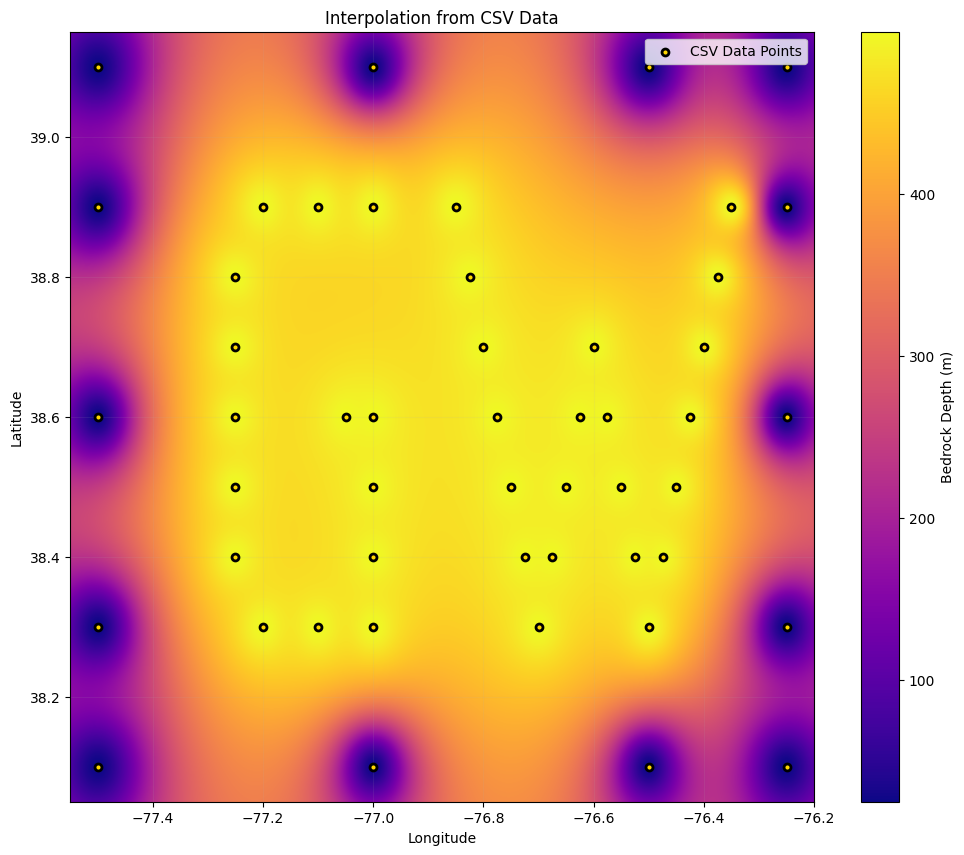

In [13]:
# Compute bounds from data
pad = 0.05  # small padding around points
bbox = (
    min(lon) - pad,  # west
    min(lat) - pad,  # south
    max(lon) + pad,  # east
    max(lat) + pad   # north
)

# Create interpolator and process
csv_interpolator = gew(
    lon=lon,
    lat=lat,
    bedrock=depth,
    epsg=4326,
    is_altitude=False
)

result, transform = csv_interpolator.interpolate_to_raster(
    bbox=bbox,
    resolution=0.001,
    output_path="bedrock_from_csv.tif",
    power=2.0
)

plt.figure(figsize=(12, 10))
plt.imshow(result, extent=[bbox[0], bbox[2], bbox[1], bbox[3]], 
           origin='upper', cmap='plasma', aspect='auto')
plt.colorbar(label='Bedrock Depth (m)')
plt.scatter(lon, lat, c='gold', s=25, edgecolors='black', 
           linewidths=2, label='CSV Data Points', zorder=5)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Interpolation from CSV Data')
plt.legend()
plt.grid(True, alpha=0.1)
plt.show()

---

# Summary

This notebook demonstrated:

1. **Basic interpolation** - Creating bedrock surfaces from point data
2. **IDW power parameter** - Controlling local vs global influence
3. **Max neighbors** - Optimizing performance and interpolation character
4. **Depth vs altitude** - Working with different data types
5. **CSV integration** - Loading real-world data

## Next Steps

- Experiment with different parameter combinations
- Integrate DEM data for altitude/depth conversion
- Validate results against known measurements

## Key Parameters to Remember

| Parameter | Effect | Recommended Values |
|-----------|--------|-------------------|
| `power` | Higher = more local | 1-3 typical, 2 standard |
| `max_neighbors` | Limits points used | 5-20 for local, None for global |
| `max_distance` | Distance threshold | Depends on data spacing |
| `resolution` | Output grid size | Match analysis needs |
| `smoothing` | Reduces singularities | 0 typical, small if needed |